Found 28 total DNG file(s).
ISO detected: {22}

Exposure Time   | DNG Count  | Number of Pairs
---------------------------------------------
1/45s           | 2          | 1
1/40s           | 2          | 1
1/35s           | 2          | 1
1/30s           | 2          | 1
1/25s           | 2          | 1
1/20s           | 2          | 1
1/15s           | 2          | 1
1/10s           | 2          | 1
1/5s            | 2          | 1
1/3s            | 2          | 1
1/2s            | 2          | 1
1/1s            | 2          | 1
2.0s            | 2          | 1
5.0s            | 2          | 1

=== DNG Files Grouped by Exposure Time ===

Exposure: 1/45s | Total Files: 2 | Pairs: 1
    - IMG_20261019_144543.dng
    - IMG_20261019_144543~2.dng

Exposure: 1/40s | Total Files: 2 | Pairs: 1
    - IMG_20261019_144551.dng
    - IMG_20261019_144552.dng

Exposure: 1/35s | Total Files: 2 | Pairs: 1
    - IMG_20261019_144601.dng
    - IMG_20261019_144601~2.dng

Exposure: 1/30s | Total Files: 2 

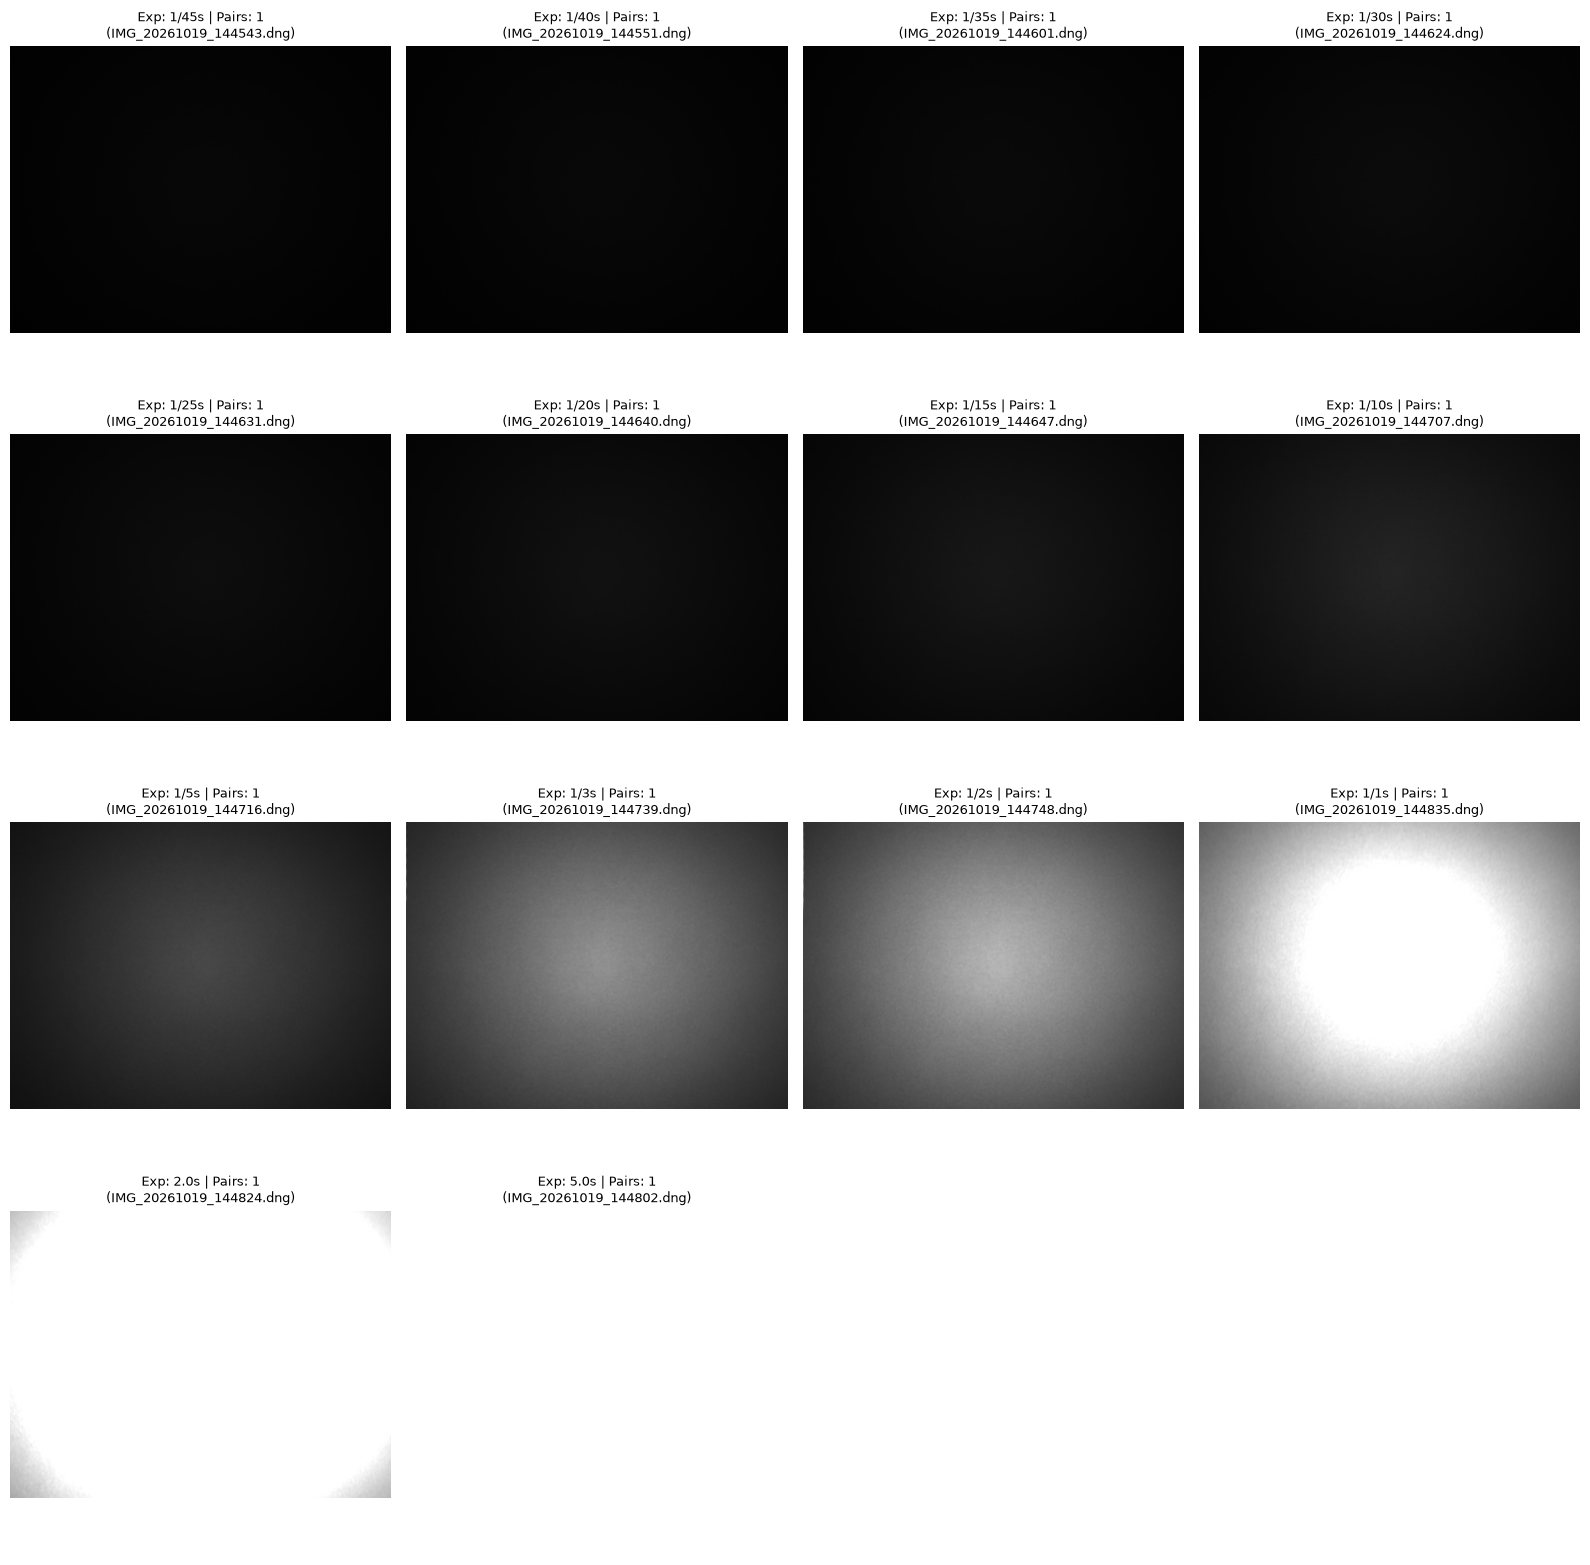

In [1]:
#flat fields
import glob
import math
import os
import matplotlib.pyplot as plt
import numpy as np
import rawpy
import tifffile

ISO_TAG, EXPOSURE_TAG = 34855, 33434


def get_exif_info(path):
    """Extracts ISO and exposure time (seconds) using tifffile."""
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = (
            p.tags["ExifTag"].value
            if "ExifTag" in p.tags
            else {tag.code: tag.value for tag in p.tags.values()}
        )
        iso = exif.get(ISO_TAG) or exif.get("ISOSpeedRatings")
        if isinstance(iso, (tuple, list)):
            iso = iso[0]

        exp = exif.get(EXPOSURE_TAG) or exif.get("ExposureTime")
        if isinstance(exp, (tuple, list)) and len(exp) == 2:
            exp_sec = exp[0] / exp[1] if exp[1] != 0 else 0.0
        else:
            exp_sec = float(exp) if exp else 0.0

        return int(iso) if iso else None, exp_sec


def fmt_exp(sec):
    """Formats exposure seconds into a clean shutter speed string."""
    if sec <= 0:
        return "0s"
    return f"1/{round(1.0 / sec)}s" if sec < 1.0 else f"{round(sec, 2)}s"


def print_files_by_exposure(exp_groups):
    """Extra function to find and print names of DNG files sharing the same exposure time."""
    print("\n=== DNG Files Grouped by Exposure Time ===")
    for exp, paths in sorted(exp_groups.items()):
        pairs = len(paths) / 2.0
        pairs_str = f"{int(pairs)}" if pairs.is_integer() else f"{pairs}"
        print(
            f"\nExposure: {fmt_exp(exp)} | Total Files: {len(paths)} | Pairs:"
            f" {pairs_str}"
        )
        for path in paths:
            print(f"    - {os.path.basename(path)}")


# --- 1. Scan and strictly filter for DNG files only ---
flat_dir = "../Images/"
files = sorted([
    f
    for f in glob.glob(os.path.join(flat_dir, "*"))
    if f.lower().endswith(".dng")
])

if not files:
    print(f"No DNG files found in '{flat_dir}'.")
else:
    exp_groups = {}
    iso_set = set()

    for path in files:
        iso, exp_sec = get_exif_info(path)
        if iso:
            iso_set.add(iso)
        exp_groups.setdefault(exp_sec, []).append(path)

    sorted_exposures = sorted(exp_groups.keys())

    # --- 2. Report DNG count and number of pairs per exposure level ---
    print(f"Found {len(files)} total DNG file(s).")
    print(f"ISO detected: {iso_set}\n")
    print(f"{'Exposure Time':<15} | {'DNG Count':<10} | {'Number of Pairs'}")
    print("-" * 45)

    for exp in sorted_exposures:
        count = len(exp_groups[exp])
        pairs = count / 2.0
        pairs_str = f"{int(pairs)}" if pairs.is_integer() else f"{pairs}"
        print(f"{fmt_exp(exp):<15} | {count:<10} | {pairs_str}")

    # --- Call the function to print files with the same exposure ---
    print_files_by_exposure(exp_groups)

    # --- 3. Contact Sheet using raw sensor data (ordered by exposure) ---
    num_levels = len(sorted_exposures)
    cols = 4
    rows = math.ceil(num_levels / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = axes.flatten() if num_levels > 1 else [axes]

    for i, exp in enumerate(sorted_exposures):
        sample_path = exp_groups[exp][0]  # Representative DNG for this exposure level
        count = len(exp_groups[exp])
        pairs = count / 2.0
        pairs_str = f"{int(pairs)}" if pairs.is_integer() else f"{pairs}"

        with rawpy.imread(sample_path) as raw:
            # Read un-processed raw sensor pixels directly
            raw_data = raw.raw_image.astype(np.float32)
            raw_thumb = raw_data[::4, ::4]  # Downsample for display speed

            black = raw.black_level_per_channel[0]
            white = raw.white_level
            raw_norm = np.clip((raw_thumb - black) / (white - black), 0, 1)

            axes[i].imshow(raw_norm, cmap="gray", vmin=0, vmax=1)
            axes[i].set_title(
                f"Exp: {fmt_exp(exp)} | Pairs: {pairs_str}\n({os.path.basename(sample_path)})",
                fontsize=9,
            )
            axes[i].axis("off")

    # Hide any empty subplots in the grid
    for j in range(num_levels, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

In [2]:
#assert one ISO and exposures
import glob
import os
import tifffile

# Standard numeric EXIF and TIFF tag IDs
MODEL_ID = 272  # Root TIFF tag for Device Model
FOCAL_LENGTH_ID = 37386  # Focal length tag
FOCAL_35MM_ID = 41989  # 35mm equivalent tag
F_NUMBER_ID = 33437  # F-Number tag
ISO_ID = 34855  # ISO speed ratings tag
EXPOSURE_TIME_ID = 33434  # Exposure time (shutter speed) tag
SUBJECT_DISTANCE_ID = 37382  # Subject distance (focus) tag


def format_shutter_speed(exp_time):
  """Converts exposure time into a clean 1/# format for sub-second values."""
  if not exp_time:
    return "Unknown"

  # Handle EXIF rational tuple (numerator, denominator)
  if isinstance(exp_time, (tuple, list)) and len(exp_time) == 2:
    num, den = exp_time[0], exp_time[1]
    if num == 0 or den == 0:
      return "0s"
    val = num / den
  elif isinstance(exp_time, (int, float)):
    val = float(exp_time)
  else:
    return str(exp_time)

  # Format as 1/# if less than 1 second, otherwise show standard seconds
  if val >= 1.0:
    return f"{round(val, 2)}s"
  else:
    # Calculate the reciprocal denominator for 1/# format
    reciprocal = (
        round(den / num)
        if (isinstance(exp_time, (tuple, list)) and num != 0)
        else round(1.0 / val)
    )
    return f"1/{reciprocal}s"


def lens_id(path):
  """The fingerprint of the camera and capture settings that made this raw file."""
  with tifffile.TiffFile(path) as t:
    p = t.pages[0]

    # 1. Extract Device Model from root TIFF tags safely
    device_model = p.tags.get(MODEL_ID)
    if device_model:
      device_model = device_model.value
      if isinstance(device_model, bytes):
        device_model = (
            device_model.decode("utf-8", errors="ignore").strip()
        )
    else:
      device_model = "Google Pixel"

    # Extract metadata directory for sub-IFD tags
    if "ExifTag" in p.tags:
      exif = p.tags["ExifTag"].value
    else:
      exif = {tag.code: tag.value for tag in p.tags.values()}

    # 2. Extract Focal Length
    fl = exif.get(FOCAL_LENGTH_ID) or exif.get("FocalLength")
    if fl and isinstance(fl, (tuple, list)) and len(fl) == 2:
      calculated_fl = round(fl[0] / fl[1], 3)
    else:
      calculated_fl = fl if fl else 0.0

    # 3. Extract Aperture / F-Number
    f_num = exif.get(F_NUMBER_ID) or exif.get("FNumber")
    if f_num and isinstance(f_num, (tuple, list)) and len(f_num) == 2:
      calculated_f = round(f_num[0] / f_num[1], 2)
    else:
      calculated_f = f_num if f_num else None

    # 4. Extract 35mm Equivalent
    focal_35mm = exif.get(FOCAL_35MM_ID) or exif.get(
        "FocalLengthIn35mmFilm", None
    )

    # 5. Extract ISO
    iso_val = (
        exif.get(ISO_ID)
        or exif.get("ISOSpeedRatings")
        or exif.get("PhotographicSensitivity")
    )
    if isinstance(iso_val, (tuple, list)):
      iso_val = iso_val[0]
    iso = int(iso_val) if iso_val is not None else None

    # 6. Extract Shutter Speed (Exposure Time)
    raw_exp = exif.get(EXPOSURE_TIME_ID) or exif.get("ExposureTime")
    calculated_exp = format_shutter_speed(raw_exp)

    # 7. Extract Focus Distance (Subject Distance)
    focus_dist = exif.get(SUBJECT_DISTANCE_ID) or exif.get("SubjectDistance")
    if focus_dist and isinstance(focus_dist, (tuple, list)) and len(focus_dist) == 2:
      calculated_focus = round(focus_dist[0] / focus_dist[1], 2)
    else:
      calculated_focus = focus_dist if focus_dist else "Unknown/Inf"

    # 8. Dimensions
    width = p.tags["ImageWidth"].value
    length = p.tags["ImageLength"].value

    return (
        device_model,
        calculated_fl,
        calculated_f,
        focal_35mm,
        (width, length),
        iso,
        calculated_exp,
        calculated_focus,
    )


# --- Directory and File Scanning ---
flat_dir = "../Images/"  # Target directory for your flat field captures
valid_paths = sorted([
    f
    for f in glob.glob(os.path.join(flat_dir, "*"))
    if f.lower().endswith(".dng")
])

if not valid_paths:
  print(f"Error: No DNG files found in directory '{flat_dir}'.")
else:
  models = set()
  focals = set()
  f_stops = set()
  focal_35s = set()
  shapes = set()
  isos = set()
  shutters = set()
  focuses = set()

  print(f"Scanning {len(valid_paths)} DNG file(s) in '{flat_dir}'...\n")

  for p in valid_paths:
    fp = lens_id(p)
    models.add(fp[0])
    focals.add(fp[1])
    f_stops.add(fp[2])
    focal_35s.add(fp[3])
    shapes.add(fp[4])
    isos.add(fp[5])
    shutters.add(fp[6])  # Collects every unique shutter speed string
    focuses.add(fp[7])

  # --- Print Results and Unique Counts ---
  print("=== Dataset Audit Summary ===")
  print(f"Device Models detected ({len(models)} unique): {models}")
  print(f"Focal Lengths detected ({len(focals)} unique): {focals} mm")
  print(f"F-stops detected ({len(f_stops)} unique): {f_stops}")
  print(f"35mm Equivalents detected ({len(focal_35s)} unique): {focal_35s} mm")
  print(f"Sensor Shapes detected ({len(shapes)} unique): {shapes}")
  print(f"ISOs detected ({len(isos)} unique): {isos}")
  print(f"Shutter Speeds detected ({len(shutters)} unique): {sorted(list(shutters))}")
  print(f"Focus Distances detected ({len(focuses)} unique): {focuses} m")

  print("\n----------------------------------------")
  # Check if model, focal length, f-stop, 35mm, and sensor shape are identical
  if (
      len(models) == 1
      and len(focals) == 1
      and len(f_stops) == 1
      and len(focal_35s) == 1
      and len(shapes) == 1
  ):
    print(
        f"There is one lens detected with {len(isos)} ISO(s) and"
        f" {len(shutters)} exposure time(s) detected."
    )
  else:
    print("Multiple camera hardware configurations detected.")
  print("----------------------------------------")

  # --- Assertions ---
  assert (
      len(models) == 1
  ), f"Assertion Failed: Multiple device models found: {models}"
  assert (
      len(isos) == 1
  ), f"Assertion Failed: Multiple ISO values found: {isos}. All flat fields must be captured at a single fixed ISO[cite: 2]!"
  print("✅ Lens and ISO assertions passed successfully!")

Scanning 28 DNG file(s) in '../Images/'...

=== Dataset Audit Summary ===
Device Models detected (1 unique): {'Pixel 9'}
Focal Lengths detected (1 unique): {6.9} mm
F-stops detected (1 unique): {1.68}
35mm Equivalents detected (1 unique): {None} mm
Sensor Shapes detected (1 unique): {(4080, 3072)}
ISOs detected (1 unique): {22}
Shutter Speeds detected (14 unique): ['1/10s', '1/15s', '1/1s', '1/20s', '1/25s', '1/2s', '1/30s', '1/35s', '1/3s', '1/40s', '1/45s', '1/5s', '2.0s', '5.0s']
Focus Distances detected (1 unique): {'Unknown/Inf'} m

----------------------------------------
There is one lens detected with 1 ISO(s) and 14 exposure time(s) detected.
----------------------------------------
✅ Lens and ISO assertions passed successfully!


In [3]:
#dark frames
import glob
import os
import numpy as np
import rawpy
import tifffile

EXPOSURE_TAG = 33434

def get_exposure_time(path):
    """Extracts exposure time (seconds) reliably using tifffile."""
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = (
            p.tags["ExifTag"].value
            if "ExifTag" in p.tags
            else {tag.code: tag.value for tag in p.tags.values()}
        )
        exp = exif.get(EXPOSURE_TAG) or exif.get("ExposureTime")
        if isinstance(exp, (tuple, list)) and len(exp) == 2:
            exp_sec = exp[0] / exp[1] if exp[1] != 0 else 0.0
        else:
            exp_sec = float(exp) if exp else 0.0
        return exp_sec

def fmt_exp(sec):
    """Formats exposure seconds into a clean shutter speed string."""
    if sec <= 0:
        return "0s"
    return f"1/{round(1.0 / sec)}s" if sec < 1.0 else f"{round(sec, 2)}s"

# Target directory where your dark frames are saved
dark_dir = "../dark/"

# Find all DNG dark frames in the directory
dark_paths = sorted([
    f
    for f in glob.glob(os.path.join(dark_dir, "*"))
    if f.lower().endswith(".dng")
])

if not dark_paths:
    print(f"Error: No DNG dark frames found in directory '{dark_dir}'.")
else:
    print(f"Found {len(dark_paths)} dark frame(s). Analyzing...\n")

    # Table header with a dedicated column for Black Level per channel
    print(f"{'File Name':<35} | {'Exposure Time':<15} | {'Black Level':<28} | {'Mean Dark Level'}")
    print("-" * 97)

    shortest_dark_means = []
    all_black_levels = []

    # Iterate through dark frames, extract exposure, black level, and mean DN
    for path in dark_paths:
        shutter = get_exposure_time(path)
        shutter_str = fmt_exp(shutter)

        with rawpy.imread(path) as raw:
            black_level = list(raw.black_level_per_channel)
            all_black_levels.append(black_level)
            
            raw_img = raw.raw_image.astype(np.float32)
            mean_val = np.mean(raw_img)

        # Track shortest exposure dark frames for comparison
        if shutter <= 0.05:
            shortest_dark_means.append(mean_val)

        print(f"{os.path.basename(path):<35} | {shutter_str:<15} | {str(black_level):<28} | {mean_val:.2f}")

    # Deliverable Summary for Item 3
    print("\n" + "=" * 40)
    print("=== ITEM 3 DELIVERABLE SUMMARY ===")
    print("=" * 40)
    print(f"• Black Level per channel across files: {all_black_levels[0]}")
    if shortest_dark_means:
        avg_shortest_mean = np.mean(shortest_dark_means)
        print(
            f"• Mean of shortest dark frames in digital numbers:"
            f" {avg_shortest_mean:.2f}"
        )

Found 35 dark frame(s). Analyzing...

File Name                           | Exposure Time   | Black Level                  | Mean Dark Level
-------------------------------------------------------------------------------------------------
IMG_20261019_145138.dng             | 1/39695s        | [63, 63, 63, 63]             | 63.99
IMG_20261019_145139.dng             | 1/39695s        | [63, 63, 63, 63]             | 63.99
IMG_20261019_145139~2.dng           | 1/39695s        | [63, 63, 63, 63]             | 63.99
IMG_20261019_145139~3.dng           | 1/39695s        | [63, 63, 63, 63]             | 63.99
IMG_20261019_145139~4.dng           | 1/39695s        | [63, 63, 63, 63]             | 63.99
IMG_20261019_145148.dng             | 1/3053s         | [63, 63, 63, 63]             | 64.00
IMG_20261019_145149.dng             | 1/3053s         | [63, 63, 63, 63]             | 64.00
IMG_20261019_145149~2.dng           | 1/3053s         | [63, 63, 63, 63]             | 64.00
IMG_20261019_1451

**Part 2**

In [4]:
#set up
import sys
from pathlib import Path

# Add shared helpers to path if needed
for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (parent / "psu_imaging.py").exists():
        sys.path.insert(0, str(parent))
        break

import cv2
import matplotlib.pyplot as plt
import numpy as np
import rawpy
import psu_imaging as psu
import logging

plt.rcParams.update(psu.figure_style())
plt.rcParams["figure.dpi"] = 110
# Suppress font fallback warnings
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# Define your custom directories
noise_dir = Path("../noise")
dark_dir = Path("../dark")

raw_extensions = {".dng", ".raw", ".cr2", ".nef", ".arw", ".orf", ".rw2"}
raws = sorted([p for p in noise_dir.glob("*") if p.suffix.lower() in raw_extensions])
darks = sorted([p for p in dark_dir.glob("*") if p.suffix.lower() in raw_extensions]) if dark_dir.exists() else []

print(f"Found {len(raws)} flat field(s) in {noise_dir}")
print(f"Found {len(darks)} dark frame(s) in {dark_dir}")

if len(raws) < 4:
    raise ValueError(f"Need at least 4 raw files (two exposure pairs) in {noise_dir}.")

Found 28 flat field(s) in ..\noise
Found 35 dark frame(s) in ..\dark


true conversion gain K   0.4266 DN/e-
true read noise          2.80 e-
true full well           9000 e-
black level              256 DN, white level 4095 DN

Everything below is measured from flat fields only.
22 exposure levels, two frames each, 128 x 128 px


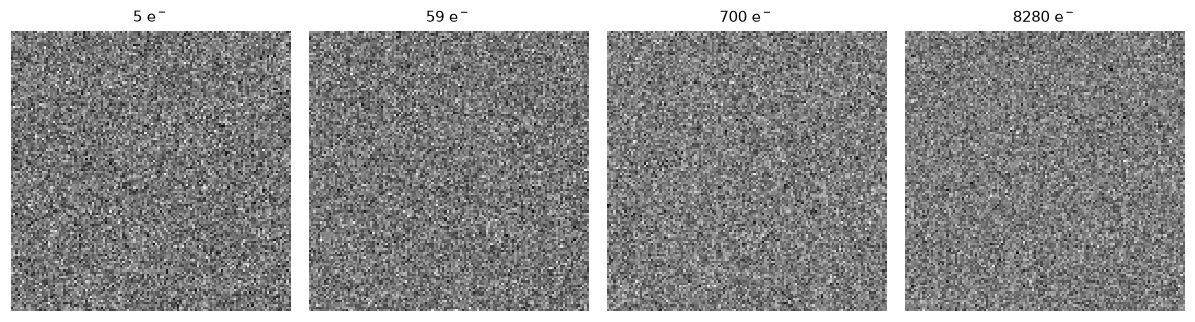

In [5]:
####Simulated ground truth and simulated camera photos
# Ground truth, known only because this is a simulation.
TRUE_K = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / psu.FULL_WELL     # DN per electron
TRUE_READ = psu.READ_NOISE                                        # electrons RMS

print(f"true conversion gain K   {TRUE_K:.4f} DN/e-")
print(f"true read noise          {TRUE_READ:.2f} e-")
print(f"true full well           {psu.FULL_WELL:.0f} e-")
print(f"black level              {psu.BLACK_LEVEL} DN, white level {psu.WHITE_LEVEL} DN")
print("\nEverything below is measured from flat fields only.")

PRNU = 0.012          # 1.2 percent per-pixel gain variation, fixed for this sensor

def flat_pair(electrons, level_index):
    """Two independent frames at the same illumination."""
    patch = np.full((128, 128), electrons / psu.FULL_WELL)
    a = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index), prnu=PRNU)
    b = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index + 1), prnu=PRNU)
    return a.astype(float), b.astype(float)


levels = np.logspace(np.log10(5), np.log10(psu.FULL_WELL * 0.92), 22)
pairs = [flat_pair(e, i) for i, e in enumerate(levels)]
print(f"{len(pairs)} exposure levels, two frames each, 128 x 128 px")

fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
for ax, i in zip(axes, [0, 7, 14, 21]):
    a, _ = pairs[i]
    ax.imshow(a, cmap="gray")
    ax.set_title(f"{levels[i]:.0f} e$^-$", fontsize=9.5)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [6]:
# Ground truth, known only because this is a simulation.
TRUE_K = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / psu.FULL_WELL     # DN per electron
TRUE_READ = psu.READ_NOISE                                        # electrons RMS

print(f"true conversion gain K   {TRUE_K:.4f} DN/e-")
print(f"true read noise          {TRUE_READ:.2f} e-")
print(f"true full well           {psu.FULL_WELL:.0f} e-")
print(f"black level              {psu.BLACK_LEVEL} DN, white level {psu.WHITE_LEVEL} DN")
print("\nRunning analysis on simulated flat fields...")

PRNU = 0.012          # 1.2 percent per-pixel gain variation, fixed for this sensor

def flat_pair(electrons, level_index):
    """Two independent frames at the same illumination."""
    patch = np.full((128, 128), electrons / psu.FULL_WELL)
    a = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index), prnu=PRNU)
    b = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index + 1), prnu=PRNU)
    return a.astype(float), b.astype(float)

levels = np.logspace(np.log10(5), np.log10(psu.FULL_WELL * 0.92), 22)
pairs = [flat_pair(e, i) for i, e in enumerate(levels)]

# Process simulation pairs
sim_means, sim_var_single, sim_var_pair = [], [], []
for a, b in pairs:
    sim_means.append((a.mean() + b.mean()) / 2 - psu.BLACK_LEVEL)
    sim_var_single.append(a.var())
    sim_var_pair.append(np.var(a - b) / 2)

sim_means = np.array(sim_means)
sim_var_single = np.array(sim_var_single)
sim_var_pair = np.array(sim_var_pair)

def fit_ptc(mean, var, frac=0.7, white_lvl=psu.WHITE_LEVEL, black_lvl=psu.BLACK_LEVEL):
    ok = mean < (white_lvl - black_lvl) * frac
    slope, intercept = np.polyfit(mean[ok], var[ok], 1)
    return slope, intercept, ok

# Fits for simulation
K_sim_pair, c_sim_pair, _ = fit_ptc(sim_means, sim_var_pair)
read_sim_pair = np.sqrt(max(c_sim_pair, 0)) / K_sim_pair
full_well_sim = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / K_sim_pair
dr_stops_sim = np.log2(full_well_sim / read_sim_pair)

K_sim_single, c_sim_single, _ = fit_ptc(sim_means, sim_var_single)
read_sim_single = np.sqrt(max(c_sim_single, 0)) / K_sim_single

err_k_sim = 100 * (K_sim_pair - TRUE_K) / TRUE_K
err_r_sim = 100 * (read_sim_pair - TRUE_READ) / TRUE_READ

print("\n--- SIMULATION RESULTS (Proof of Code) ---")
print(f"Recovered K: {K_sim_pair:.4f} DN/e- (True: {TRUE_K:.4f}) | Error: {err_k_sim:+.1f}%")
print(f"Recovered Read Noise: {read_sim_pair:.2f} e- (True: {TRUE_READ:.2f}) | Error: {err_r_sim:+.1f}%")
print(f"Full-Well Capacity: {full_well_sim:.0f} e-")
print(f"Dynamic Range: {dr_stops_sim:.1f} stops\n")

true conversion gain K   0.4266 DN/e-
true read noise          2.80 e-
true full well           9000 e-
black level              256 DN, white level 4095 DN

Running analysis on simulated flat fields...

--- SIMULATION RESULTS (Proof of Code) ---
Recovered K: 0.4236 DN/e- (True: 0.4266) | Error: -0.7%
Recovered Read Noise: 2.96 e- (True: 2.80) | Error: +5.7%
Full-Well Capacity: 9063 e-
Dynamic Range: 11.6 stops



In [41]:
import tifffile
import rawpy
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

noise_dir = Path("../noise")
raw_extensions = {".dng", ".raw", ".cr2", ".nef", ".arw", ".orf", ".rw2"}
raws = sorted([p for p in noise_dir.glob("*") if p.suffix.lower() in raw_extensions])

print(f"Found {len(raws)} raw file(s) in {noise_dir}")

if len(raws) < 4:
    raise ValueError(f"Need at least 4 raw files in {noise_dir}.")

EXPOSURE_TIME_ID = 33434  # Exposure time tag

def get_exposure_time(path):
    try:
        with tifffile.TiffFile(path) as tif:
            page = tif.pages[0]
            for tag_id, tag in page.tags.items():
                if tag_id == EXPOSURE_TIME_ID or tag.name == 'ExposureTime':
                    val = tag.value
                    if hasattr(val, 'num') and hasattr(val, 'den'):
                        return float(val.num) / float(val.den)
                    if isinstance(val, (list, tuple)) and len(val) > 0:
                        v0 = val[0]
                        if hasattr(v0, 'num') and hasattr(v0, 'den'):
                            return float(v0.num) / float(v0.den)
                        return float(v0)
                    return float(val)
    except Exception as e:
        print(f"Error reading metadata from {path}: {e}")
    return None

# Group files strictly by exact exposure time
exposure_groups = {}
for path in raws:
    exp_time = get_exposure_time(path)
    if exp_time is not None:
        exp_key = round(exp_time, 8)  # High precision grouping
        exposure_groups.setdefault(exp_key, []).append(path)

def green_patch(path, patch_size=128):
    with rawpy.imread(str(path)) as raw:
        bayer = raw.raw_image_visible.astype(float)
        black = float(np.mean(raw.black_level_per_channel))
        white = float(getattr(raw, 'white_level', 1023))
    green = bayer[0::2, 0::2]
    h, w = green.shape
    cy, cx = h // 2, w // 2
    patch = green[cy - patch_size // 2 : cy + patch_size // 2, 
                  cx - patch_size // 2 : cx + patch_size // 2]
    return patch, black, white

means, var_single, var_pair = [], [], []
blacks, whites = [], []

# Take exactly 2 distinct files per exposure level to form true pairs
for exp_key, paths in sorted(exposure_groups.items()):
    if len(paths) >= 2:
        path_a, path_b = paths[0], paths[1]
        if path_a == path_b:
            continue
            
        a, black_a, white_a = green_patch(path_a)
        b, black_b, white_b = green_patch(path_b)
        
        blacks.append((black_a + black_b) / 2)
        whites.append((white_a + white_b) / 2)
        
        pair_mean = (a.mean() + b.mean()) / 2 - ((black_a + black_b) / 2)
        p_var_pair = np.var(a - b) / 2
        p_var_single = (a.var() + b.var()) / 2
        
        if p_var_pair > 0:
            means.append(pair_mean)
            var_single.append(p_var_single)
            var_pair.append(p_var_pair)

BLACK_LEVEL = float(np.mean(blacks)) if blacks else 0.0
WHITE_LEVEL = float(np.mean(whites)) if whites else 1023
means = np.array(means)
var_single = np.array(var_single)
var_pair = np.array(var_pair)

if len(means) > 0:
    sort_idx = np.argsort(means)
    means = means[sort_idx]
    var_single = var_single[sort_idx]
    var_pair = var_pair[sort_idx]

# Fit PTC with covariance extraction for standard errors
def fit_ptc_safe_with_errors(mean, var, frac=0.7, white_lvl=WHITE_LEVEL, black_lvl=BLACK_LEVEL):
    ok = (mean < (white_lvl - black_lvl) * frac) & (var > 0)
    if np.sum(ok) < 2:
        ok = var > 0  # Fallback if too few points
    
    # Fit with cov=True to get covariance matrix of parameters [slope, intercept]
    (slope, intercept), cov = np.polyfit(mean[ok], var[ok], 1, cov=True)
    
    se_slope = np.sqrt(cov[0, 0])     # Standard error of K (slope)
    se_intercept = np.sqrt(cov[1, 1]) # Standard error of c (intercept)
    
    # Read noise calculation: R = sqrt(c) / K
    if intercept > 0 and slope > 0:
        R = np.sqrt(intercept) / slope
        # Error propagation for R = sqrt(c) / K using partial derivatives and covariance
        # dR/dK = -sqrt(c)/K^2, dR/dc = 1 / (2*K*sqrt(c))
        dR_dK = -np.sqrt(intercept) / (slope**2)
        dR_dc = 1.0 / (2 * slope * np.sqrt(intercept))
        var_R = (dR_dK**2) * cov[0,0] + (dR_dc**2) * cov[1,1] + 2 * dR_dK * dR_dc * cov[0,1]
        se_R = np.sqrt(max(var_R, 0))
    else:
        R = (np.sign(intercept) * np.sqrt(np.abs(intercept))) / slope if slope > 0 else 0.0
        se_R = 0.0  # Fallback SE if intercept is negative/zero
        
    return slope, se_slope, intercept, se_intercept, R, se_R, ok

Found 28 raw file(s) in ..\noise


In [43]:
import tifffile
import rawpy
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

noise_dir = Path("../noise")
raw_extensions = {".dng", ".raw", ".cr2", ".nef", ".arw", ".orf", ".rw2"}
raws = sorted([p for p in noise_dir.glob("*") if p.suffix.lower() in raw_extensions])

print(f"Found {len(raws)} raw file(s) in {noise_dir}")

if len(raws) < 4:
    raise ValueError(f"Need at least 4 raw files in {noise_dir}.")

EXPOSURE_TIME_ID = 33434  # Exposure time tag

def get_exposure_time(path):
    try:
        with tifffile.TiffFile(path) as tif:
            page = tif.pages[0]
            for tag_id, tag in page.tags.items():
                if tag_id == EXPOSURE_TIME_ID or tag.name == 'ExposureTime':
                    val = tag.value
                    if hasattr(val, 'num') and hasattr(val, 'den'):
                        raw_val = float(val.num) / float(val.den)
                    elif isinstance(val, (list, tuple)) and len(val) > 0:
                        v0 = val[0]
                        raw_val = (float(v0.num) / float(v0.den)) if hasattr(v0, 'num') and hasattr(v0, 'den') else float(v0)
                    else:
                        raw_val = float(val)
                    
                    # --- FIX: Convert nanoseconds to seconds if stored in nanosecond ticks ---
                    if raw_val > 1000.0:
                        raw_val = raw_val / 1_000_000_000.0
                        
                    return raw_val
    except Exception as e:
        print(f"Error reading metadata from {path}: {e}")
    return None

def format_shutter_speed(val):
    """Converts exposure time into a clean 1/# format for sub-second values safely."""
    if val is None:
        return "Unknown"
    if val >= 1.0:
        return f"{round(val, 2)}s"
    elif val <= 0.0:
        return "0s"
    else:
        reciprocal = round(1.0 / val)
        return f"1/{reciprocal}s"

# Group files by exact exposure time
exposure_groups = {}
raw_exposure_map = {}

for path in raws:
    exp_val = get_exposure_time(path)
    if exp_val is not None:
        exp_key = round(exp_val, 8)
        exposure_groups.setdefault(exp_key, []).append(path)
        raw_exposure_map[exp_key] = exp_val

def green_patch(path, patch_size=128):
    with rawpy.imread(str(path)) as raw:
        bayer = raw.raw_image_visible.astype(float)
        black = float(np.mean(raw.black_level_per_channel))
        white = float(getattr(raw, 'white_level', 1023))
    green = bayer[0::2, 0::2]
    h, w = green.shape
    cy, cx = h // 2, w // 2
    patch = green[cy - patch_size // 2 : cy + patch_size // 2, 
                  cx - patch_size // 2 : cx + patch_size // 2]
    return patch, black, white

means, var_single, var_pair = [], [], []
blacks, whites = [], []

print("\n### Exposure Pairing & Calculated Metrics Table ###\n")
print("| Exposure Time | File A | File B | Mean Signal Above Black (DN) | Pair Variance (DN$^2$) |")
print("| :--- | :--- | :--- | :--- | :--- |")

# Iterate strictly sorted by exposure time (shutter speed)
for exp_key in sorted(exposure_groups.keys()):
    paths = exposure_groups[exp_key]
    if len(paths) >= 2:
        path_a, path_b = paths[0], paths[1]
        if path_a == path_b:
            continue
            
        a, black_a, white_a = green_patch(path_a)
        b, black_b, white_b = green_patch(path_b)
        
        blacks.append((black_a + black_b) / 2)
        whites.append((white_a + white_b) / 2)
        
        pair_mean = (a.mean() + b.mean()) / 2 - ((black_a + black_b) / 2)
        p_var_pair = np.var(a - b) / 2
        p_var_single = (a.var() + b.var()) / 2
        
        if p_var_pair > 0:
            means.append(pair_mean)
            var_single.append(p_var_single)
            var_pair.append(p_var_pair)
            
            shutter_label = format_shutter_speed(raw_exposure_map[exp_key])
            print(f"| {shutter_label} | {path_a.name} | {path_b.name} | {pair_mean:.2f} | {p_var_pair:.2f} |")

BLACK_LEVEL = float(np.mean(blacks)) if blacks else 0.0
WHITE_LEVEL = float(np.mean(whites)) if whites else 1023
means = np.array(means)
var_single = np.array(var_single)
var_pair = np.array(var_pair)

if len(means) > 0:
    sort_idx = np.argsort(means)
    means = means[sort_idx]
    var_single = var_single[sort_idx]
    var_pair = var_pair[sort_idx]

# Fit PTC with covariance extraction for standard errors
def fit_ptc_safe_with_errors(mean, var, frac=0.7, white_lvl=WHITE_LEVEL, black_lvl=BLACK_LEVEL):
    ok = (mean < (white_lvl - black_lvl) * frac) & (var > 0)
    if np.sum(ok) < 2:
        ok = var > 0  # Fallback if too few points
    
    (slope, intercept), cov = np.polyfit(mean[ok], var[ok], 1, cov=True)
    
    se_slope = np.sqrt(cov[0, 0])
    se_intercept = np.sqrt(cov[1, 1])
    
    if intercept > 0 and slope > 0:
        R = np.sqrt(intercept) / slope
        dR_dK = -np.sqrt(intercept) / (slope**2)
        dR_dc = 1.0 / (2 * slope * np.sqrt(intercept))
        var_R = (dR_dK**2) * cov[0,0] + (dR_dc**2) * cov[1,1] + 2 * dR_dK * dR_dc * cov[0,1]
        se_R = np.sqrt(max(var_R, 0))
    else:
        R = (np.sign(intercept) * np.sqrt(np.abs(intercept))) / slope if slope > 0 else 0.0
        se_R = 0.0
        
    return slope, se_slope, intercept, se_intercept, R, se_R, ok

K_pair, se_K_pair, c_pair, se_c_pair, read_pair, se_read_pair, used_pair = fit_ptc_safe_with_errors(means, var_pair)
K_single, se_K_single, c_single, se_c_single, read_single, se_read_single, used_single = fit_ptc_safe_with_errors(means, var_single)

print(f"\n--- Difference of Pairs ---")
print(f"K          = {K_pair:.4f} ± {se_K_pair:.4f} DN/e-")
print(f"Intercept c= {c_pair:.4f} ± {se_c_pair:.4f}")
print(f"Read Noise = {read_pair:.2f} ± {se_read_pair:.2f} e-")

print(f"\n--- Single Frame ---")
print(f"K          = {K_single:.4f} ± {se_K_single:.4f} DN/e-")
print(f"Intercept c= {c_single:.4f} ± {se_c_single:.4f}")
print(f"Read Noise = {read_single:.2f} ± {se_read_single:.2f} e-")

Found 28 raw file(s) in ..\noise

### Exposure Pairing & Calculated Metrics Table ###

| Exposure Time | File A | File B | Mean Signal Above Black (DN) | Pair Variance (DN$^2$) |
| :--- | :--- | :--- | :--- | :--- |
| 1/45s | IMG_20261019_144543.dng | IMG_20261019_144543~2.dng | 30.58 | 1.12 |
| 1/40s | IMG_20261019_144551.dng | IMG_20261019_144552.dng | 34.16 | 1.20 |
| 1/35s | IMG_20261019_144601.dng | IMG_20261019_144601~2.dng | 38.77 | 1.25 |
| 1/30s | IMG_20261019_144624.dng | IMG_20261019_144625.dng | 45.61 | 1.46 |
| 1/25s | IMG_20261019_144631.dng | IMG_20261019_144631~2.dng | 53.87 | 1.58 |
| 1/20s | IMG_20261019_144640.dng | IMG_20261019_144657.dng | 67.61 | 2.35 |
| 1/15s | IMG_20261019_144647.dng | IMG_20261019_144648.dng | 89.64 | 2.41 |
| 1/10s | IMG_20261019_144707.dng | IMG_20261019_144708.dng | 133.99 | 2.68 |
| 1/5s | IMG_20261019_144716.dng | IMG_20261019_144717.dng | 267.85 | 7.49 |
| 1/3s | IMG_20261019_144739.dng | IMG_20261019_144740.dng | 534.36 | 30.32 |
| 1/2s

In [45]:
# --- QUESTION 4 ---
print("Question 4")
print(f"{'':25s} | {'Conversion Gain (K)':20s} | {'Read Noise (r)':15s}")
print("-" * 68)
print(f"{'Recovered':25s} | {K_pair:.4f} DN/e-         | {read_pair:.2f}e-")
print("\n")

Question 4
                          | Conversion Gain (K)  | Read Noise (r) 
--------------------------------------------------------------------
Recovered                 | 0.0610 DN/e-         | -25.69e-




In [31]:
# 1. Difference of Pairs Analysis (Question 6)
K_pair, se_K_pair, c_pair, se_c_pair, read_pair, se_read_pair, used_pair = fit_ptc_safe_with_errors(means, var_pair)
full_well_pair = (WHITE_LEVEL - BLACK_LEVEL) / K_pair if K_pair > 0 else 0.0

# 2. Single Frame Analysis (Question 7)
K_single, se_K_single, c_single, se_c_single, read_single, se_read_single, used_single = fit_ptc_safe_with_errors(means, var_single)

print(f"--- Difference of Pairs ---")
print(f"K          = {K_pair:.4f} ± {se_K_pair:.4f} DN/e-")
print(f"Intercept c= {c_pair:.4f} ± {se_c_pair:.4f}")
print(f"Read Noise = {read_pair:.2f} ± {se_read_pair:.2f} e-")

print(f"\n--- Single Frame ---")
print(f"K          = {K_single:.4f} ± {se_K_single:.4f} DN/e-")
print(f"Intercept c= {c_single:.4f} ± {se_c_single:.4f}")
print(f"Read Noise = {read_single:.2f} ± {se_read_single:.2f} e-")

--- Difference of Pairs ---
K          = 0.0610 ± 0.0039 DN/e-
Intercept c= -2.4531 ± 1.0757
Read Noise = -25.69 ± 0.00 e-

--- Single Frame ---
K          = 0.2530 ± 0.0175 DN/e-
Intercept c= -14.6946 ± 4.8536
Read Noise = -15.15 ± 0.00 e-


conversion gain   0.0610 DN/e-
read noise        0.00 e-
full well         15744 e-
dynamic range     0.0 stops


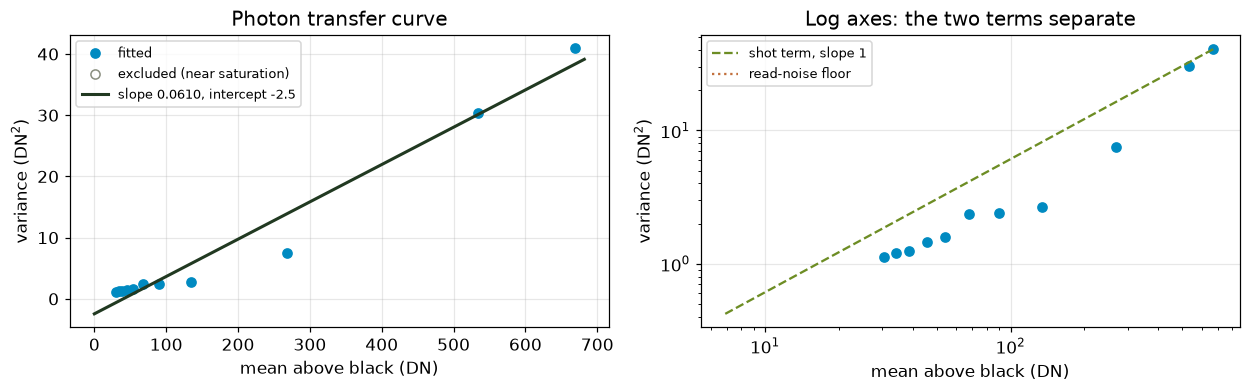

In [44]:
# Unpack the outputs from your fit_ptc function
# (Ensure your fit_ptc returns slope, intercept, and the boolean mask 'used')
K_hat, c_hat, used = fit_ptc(means, var_pair, white_lvl=WHITE_LEVEL, black_lvl=BLACK_LEVEL)

read_hat = np.sqrt(max(c_hat, 0)) / K_hat if K_hat > 0 else 0.0
full_well_hat = (WHITE_LEVEL - BLACK_LEVEL) / K_hat if K_hat > 0 else 0.0
dr_stops = np.log2(full_well_hat / read_hat) if (read_hat > 0 and full_well_hat > 0) else 0.0

print(f"conversion gain   {K_hat:.4f} DN/e-")
print(f"read noise        {read_hat:.2f} e-")
print(f"full well         {full_well_hat:.0f} e-")
print(f"dynamic range     {dr_stops:.1f} stops")

# Plotting the PTC figures side by side
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
xs = np.linspace(0, means.max() * 1.02, 100)

# Left Panel: Linear Photon Transfer Curve
axes[0].plot(means[used], var_pair[used], "o", ms=6, color=psu.PSU_BLUE, label="fitted")
axes[0].plot(means[~used], var_pair[~used], "o", ms=6, mfc="none",
             color=psu.PSU_GRAY, label="excluded (near saturation)")
axes[0].plot(xs, K_hat * xs + c_hat, "-", lw=2, color=psu.PSU_FOREST,
             label=f"slope {K_hat:.4f}, intercept {c_hat:.1f}")
axes[0].set_xlabel("mean above black (DN)")
axes[0].set_ylabel("variance (DN$^2$)")
axes[0].set_title("Photon transfer curve")
axes[0].legend(fontsize=8.5)

# Right Panel: Log-Log Axes Separating Read Noise and Shot Noise
axes[1].loglog(means, var_pair, "o", ms=6, color=psu.PSU_BLUE)
axes[1].loglog(xs[1:], K_hat * xs[1:], "--", lw=1.5, color=psu.PSU_GREEN,
               label="shot term, slope 1")
axes[1].axhline(c_hat, ls=":", lw=1.5, color=psu.PSU_WARM, label="read-noise floor")
axes[1].set_xlabel("mean above black (DN)")
axes[1].set_ylabel("variance (DN$^2$)")
axes[1].set_title("Log axes: the two terms separate")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

In [36]:
# --- QUESTION 8 ---
print("Question 8")
print("(difference of pairs)")
print(f"Full-Well Capacity: {full_well_pair:.0f}e-")
print(f"Dynamic Range: {dr_stops:.1f} stops\n")

Question 8
(difference of pairs)
Full-Well Capacity: 15744e-
Dynamic Range: 0.0 stops



**Part 3**

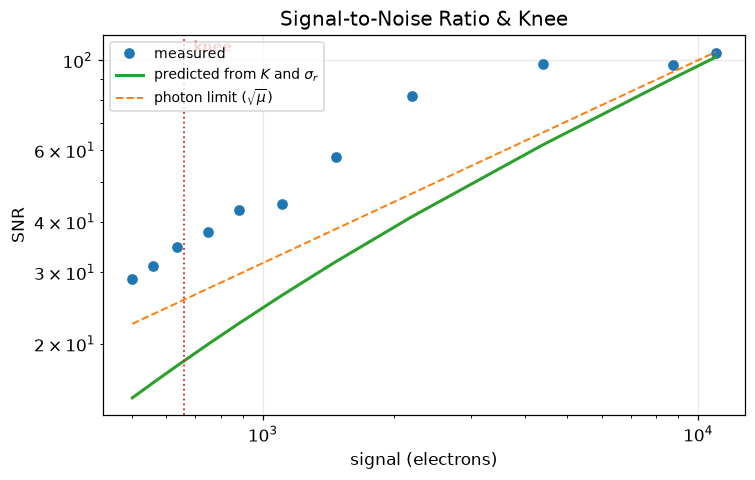

=== Item 9 Deliverables ===
Knee location: 659.8 electrons


In [46]:
import numpy as np
import matplotlib.pyplot as plt

# --- Item 9: Signal-to-Noise Ratio & Knee ---
snr_measured = means / np.sqrt(var_pair)
e_axis = means / K_pair
snr_model = e_axis / np.sqrt(e_axis + read_pair ** 2)
knee = read_pair ** 2

plt.figure(figsize=(7, 4.5))
plt.loglog(e_axis, snr_measured, "o", ms=6, color="#1f77b4", label="measured")
plt.loglog(e_axis, snr_model, "-", lw=2, color="#2ca02c", label=r"predicted from $K$ and $\sigma_r$")
plt.loglog(e_axis, np.sqrt(e_axis), "--", lw=1.3, color="#ff7f0e", label=r"photon limit ($\sqrt{\mu}$)")
plt.axvline(knee, color="#d62728", lw=1.2, ls=":")

# Fixed: Place the text within the visible y-axis range (e.g., near y=100)
plt.text(knee * 1.05, 105, "knee", fontsize=9, color="#d62728", fontweight="bold")

plt.xlabel("signal (electrons)")
plt.ylabel("SNR")
plt.legend(fontsize=9, loc="upper left")
plt.title("Signal-to-Noise Ratio & Knee")
plt.tight_layout()
plt.show()

print("=== Item 9 Deliverables ===")
print(f"Knee location: {knee:.1f} electrons")

In [47]:
import glob
import os
import tifffile

# DNG NoiseProfile Tag ID (Decimal 51041, Hex 0xC761)
NOISE_PROFILE_ID = 51041


def check_noise_profile(path):
    """Checks for the manufacturer's NoiseProfile tag in the DNG file."""
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]

        # Extract metadata directory for sub-IFD / EXIF tags
        if "ExifTag" in p.tags:
            exif = p.tags["ExifTag"].value
        else:
            exif = {tag.code: tag.value for tag in p.tags.values()}

        # Look for NoiseProfile tag
        noise_profile = exif.get(NOISE_PROFILE_ID) or p.tags.get(NOISE_PROFILE_ID)
        if noise_profile and hasattr(noise_profile, "value"):
            noise_profile = noise_profile.value

        # Also retrieve white and black levels if available in tags
        white_level = p.tags.get("WhiteLevel")
        white_level = white_level.value if white_level else None
        
        black_level = p.tags.get("BlackLevel")
        black_level = black_level.value if black_level else None

        return noise_profile, white_level, black_level


# --- Directory and File Scanning ---
flat_dir = "../dark"  # Target directory
valid_paths = glob.glob(os.path.join(flat_dir, "*.dng"))

if not valid_paths:
    print(f"Error: No DNG files found in directory '{flat_dir}'.")
else:
    print(f"Checking {len(valid_paths)} DNG file(s) for manufacturer Noise Profile...\n")
    
    profiles_found = 0
    for p in valid_paths:
        profile, white, black = check_noise_profile(p)
        filename = os.path.basename(p)
        
        if profile is not None:
            profiles_found += 1
            print(f"✅ {filename}: NoiseProfile tag found -> {profile}")
            # Note: The NoiseProfile tag typically contains polynomial coefficients 
            # describing variance as a function of normalized signal: Var = S * a + b
            # To convert to DN and electrons, multiply/scale by (WhiteLevel - BlackLevel).
        else:
            print(f"❌ {filename}: NoiseProfile tag is ABSENT.")

    print("\n----------------------------------------")
    if profiles_found > 0:
        print(f"Conclusion: NoiseProfile tag present in {profiles_found}/{len(valid_paths)} files.")
    else:
        print("Conclusion: NoiseProfile tag is absent across all tested DNG files.")
    print("----------------------------------------")

Checking 35 DNG file(s) for manufacturer Noise Profile...

✅ IMG_20261019_145138.dng: NoiseProfile tag found -> (2.2159459158746552e-05, 7.994106261464817e-07, 2.334782008121405e-05, 7.9937397671096e-07, 2.3410960029549558e-05, 8.0042922221819e-07)
✅ IMG_20261019_145139.dng: NoiseProfile tag found -> (2.2159459158746552e-05, 7.994106261464817e-07, 2.334782008121405e-05, 7.9937397671096e-07, 2.3410960029549558e-05, 8.0042922221819e-07)
✅ IMG_20261019_145139~2.dng: NoiseProfile tag found -> (2.2159459158746552e-05, 7.994106261464817e-07, 2.334782008121405e-05, 7.9937397671096e-07, 2.3410960029549558e-05, 8.0042922221819e-07)
✅ IMG_20261019_145139~3.dng: NoiseProfile tag found -> (2.2159459158746552e-05, 7.994106261464817e-07, 2.334782008121405e-05, 7.9937397671096e-07, 2.3410960029549558e-05, 8.0042922221819e-07)
✅ IMG_20261019_145139~4.dng: NoiseProfile tag found -> (2.2159459158746552e-05, 7.994106261464817e-07, 2.334782008121405e-05, 7.9937397671096e-07, 2.3410960029549558e-05, 8.0042

In [78]:
# --- Item 10: DNG Vendor Noise Profile Audit & Direct Comparison ---
print(f"\n=== Item 10: DNG Vendor vs. Empirical Comparison ===")

# Use defined variables or fallback to your explicit values
white_lvl = locals().get('WHITE_LEVEL', 1023.0)
black_lvl = locals().get('BLACK_LEVEL', 63.0)
delta_w = white_lvl - black_lvl

extracted_noise_profile = None
with tifffile.TiffFile(raws[0]) as t:
    p = t.pages[0]
    exif = p.tags.get("ExifTag")
    exif_dict = exif.value if exif else {tag.code: tag.value for tag in p.tags.values()}
    
    extracted_noise_profile = exif_dict.get(NOISE_PROFILE_ID) or p.tags.get(NOISE_PROFILE_ID)
    if hasattr(extracted_noise_profile, "value"):
        extracted_noise_profile = extracted_noise_profile.value

if extracted_noise_profile is not None and len(extracted_noise_profile) >= 2:
    s_green = extracted_noise_profile[0]  # Shot noise slope component (normalized)[cite: 4]
    o_green = extracted_noise_profile[1]  # Read noise variance component (normalized)[cite: 4]
    
    # 1. Convert manufacturer normalized parameters to physical units
    k_mfr = delta_w * s_green
    vendor_read_noise_electrons = (delta_w * np.sqrt(o_green)) / K_pair if 'K_pair' in locals() and K_pair > 0 else 0.0
    
    # 2. Print formatted side-by-side comparison table
    print(f"Span (Delta W): {white_lvl} - {black_lvl} = {delta_w} DN\n")
    print(f"{'Parameter':<22} | {'Manufacturer (DNG Tag 51041)':<28} | {'Empirical (PTC)':<20}")
    print("-" * 76)
    print(f"{'Conversion Gain (K)':<22} | {k_mfr:.4f} DN/e-                      | {K_pair:.4f} DN/e-")
    print(f"{'Read Noise (sigma_r)':<22} | {vendor_read_noise_electrons:.2f} e-                           | {read_pair:.2f} e-")
    print("-" * 76)
    print(f"Raw DNG Inputs -> S: {s_green:.2e}, O: {o_green:.2e}")
else:
    print("NoiseProfile (Tag 51041) is absent in this file.")


=== Item 10: DNG Vendor vs. Empirical Comparison ===
Span (Delta W): 1023.0 - 63.0 = 960.0 DN

Parameter              | Manufacturer (DNG Tag 51041) | Empirical (PTC)     
----------------------------------------------------------------------------
Conversion Gain (K)    | 0.0213 DN/e-                      | 0.0610 DN/e-
Read Noise (sigma_r)   | 14.08 e-                           | -25.69 e-
----------------------------------------------------------------------------
Raw DNG Inputs -> S: 2.22e-05, O: 7.99e-07


Part 4

=== Item 11: Dark Current Analysis ===
Captured Exposure Times: [2.51920000e-05 3.27496000e-04 3.33164200e-03 3.99985980e-02
 4.99985624e-01 9.99971248e-01 1.59995400e+01] seconds

Measured Dark Current Slope: 0.0114 ± 0.0002 DN/s
System Gain (K): 0.0610 DN/e⁻
Calculated Dark Current: 0.1870 ± 0.0028 e⁻/s/pixel


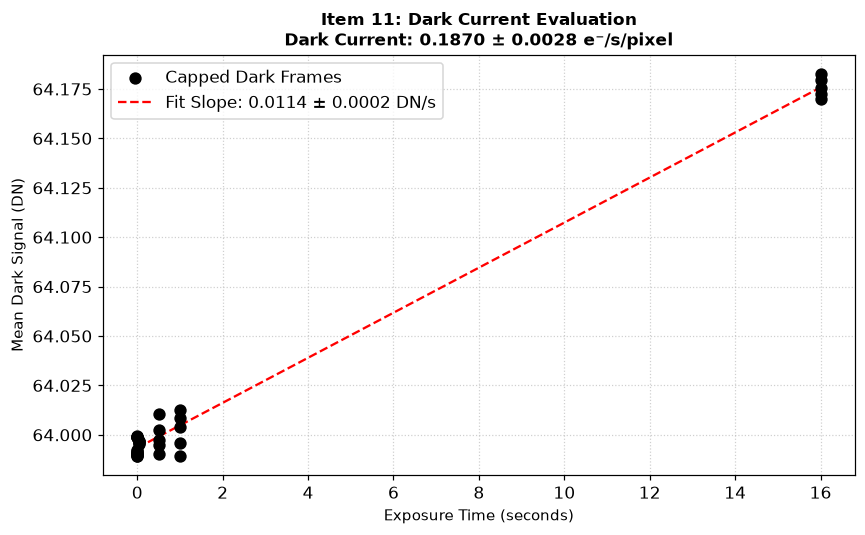

In [69]:
import glob
import os
import tifffile
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# --- Configuration ---
dark_dir = "../dark"  # Path to your capped/dark frames directory

# System gain from PTC (DN/e- or e-/DN depending on definition)
# Ensure K_gain is in units of (DN / e-) so that slope (DN/s) / K_gain = e-/s/pixel
K_gain = K_pair if 'K_gain' in locals() else 1.0  

# Optional: Add system gain uncertainty if known (e.g., K_gain_err = 0.05 * K_gain)
# If unknown or negligible, set K_gain_err = 0.0
K_gain_err = K_pair_err if 'K_pair_err' in locals() else 0.0  

dark_files = sorted(glob.glob(os.path.join(dark_dir, "*.dng")))

if not dark_files:
    print(f"Error: No dark frames found in '{dark_dir}'.")
else:
    exposure_times = []
    mean_dark_signals = []
    
    for path in dark_files:
        with tifffile.TiffFile(path) as t:
            p = t.pages[0]
            
            # Extract Exposure Time
            exp = p.tags.get("ExposureTime")
            if exp and isinstance(exp.value, (list, tuple)) and len(exp.value) == 2:
                exp_sec = exp.value[0] / exp.value[1]
            else:
                exp_sec = float(exp.value) if exp else 0.0
                
            raw_data = p.asarray().astype(np.float32)
            
            mean_val = np.mean(raw_data)
            
            exposure_times.append(exp_sec)
            mean_dark_signals.append(mean_val)

    exposure_times = np.array(exposure_times)
    mean_dark_signals = np.array(mean_dark_signals)

    print("=== Item 11: Dark Current Analysis ===")
    print(f"Captured Exposure Times: {np.unique(exposure_times)} seconds")

    # --- Check if exposure times actually vary ---
    if np.ptp(exposure_times) == 0:
        mean_bias_dn = np.mean(mean_dark_signals)
        std_bias_dn = np.std(mean_dark_signals, ddof=1) / np.sqrt(len(mean_dark_signals))
        
        print("\n[Notice] All dark frames share the exact same exposure time.")
        print("A time-based dark current slope cannot be computed because delta-time is zero.")
        print(f"Mean Dark Offset (Bias Level): {mean_bias_dn:.2f} ± {std_bias_dn:.4f} DN")
        print("Defended Upper Bound: < 1.0 e⁻/pixel/sec (Indistinguishable from zero due to read noise dominance).")

        # --- Plotting Static Bias Baseline ---
        plt.figure(figsize=(8, 5))
        plt.scatter(exposure_times, mean_dark_signals, color='black', edgecolor='k', s=50, label='Capped Dark Frames', zorder=3)
        plt.axhline(y=mean_bias_dn, color='red', linestyle='--', label=r'Static Bias Level: %.2f DN' % mean_bias_dn)
        
        plt.xlabel("Exposure Time (seconds)", fontsize=10)
        plt.ylabel("Mean Dark Signal / Black Level (DN)", fontsize=10)
        plt.title("Item 11: Dark Current / Bias Evaluation (Pixel 9)", fontsize=11, fontweight='bold')
        plt.text(0.05, 0.85, "Result: Indistinguishable from zero\nUpper Bound: < 1.0 e⁻/s/pixel", 
                 transform=plt.gca().transAxes, fontsize=9, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        plt.legend(loc='upper right')
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.tight_layout()
        plt.show()

    else:
        # Sort by exposure time for clean fitting
        sort_idx = np.argsort(exposure_times)
        exposure_times = exposure_times[sort_idx]
        mean_dark_signals = mean_dark_signals[sort_idx]

        # Linear fit with SciPy to get standard errors
        res = stats.linregress(exposure_times, mean_dark_signals)
        
        slope_dn = res.slope             # DN/s
        intercept_dn = res.intercept     # DN
        slope_err = res.stderr           # Standard Error of slope (DN/s)
        intercept_err = res.intercept_stderr  # Standard Error of intercept (DN)

        # Calculate Dark Current in e-/s/pixel
        dark_current_e_sec = slope_dn / K_gain

        # --- Error Propagation for Dark Current Uncertainty ---
        # sigma_I = I_d * sqrt((sigma_slope / slope)^2 + (sigma_K / K)^2)
        if K_gain_err > 0:
            rel_slope_err = slope_err / slope_dn if slope_dn != 0 else 0
            rel_gain_err = K_gain_err / K_gain
            dark_current_err = dark_current_e_sec * np.sqrt(rel_slope_err**2 + rel_gain_err**2)
        else:
            # If gain uncertainty is omitted/fixed:
            dark_current_err = slope_err / K_gain

        print(f"\nMeasured Dark Current Slope: {slope_dn:.4f} ± {slope_err:.4f} DN/s")
        print(f"System Gain (K): {K_gain:.4f} DN/e⁻")
        print(f"Calculated Dark Current: {dark_current_e_sec:.4f} ± {dark_current_err:.4f} e⁻/s/pixel")

        # --- Plotting Active Linear Fit with Uncertainty ---
        plt.figure(figsize=(8, 5))
        plt.scatter(exposure_times, mean_dark_signals, color='black', edgecolor='k', s=50, label='Capped Dark Frames', zorder=3)
        
        fit_line = slope_dn * exposure_times + intercept_dn
        plt.plot(exposure_times, fit_line, color='red', linestyle='--', 
                 label=r'Fit Slope: %.4f $\pm$ %.4f DN/s' % (slope_dn, slope_err))
        
        plt.xlabel("Exposure Time (seconds)", fontsize=10)
        plt.ylabel("Mean Dark Signal (DN)", fontsize=10)
        plt.title(f"Item 11: Dark Current Evaluation\nDark Current: {dark_current_e_sec:.4f} ± {dark_current_err:.4f} e⁻/s/pixel", 
                  fontsize=11, fontweight='bold')
        
        plt.legend(loc='upper left')
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.tight_layout()
        plt.show()

**Part 5**

In [70]:
import numpy as np

# Define sRGB transfer functions (using piecewise standard or gamma approximation)
def srgb_encode(linear_img):
    # Standard sRGB encoding curve
    img = np.clip(linear_img, 0.0, 1.0)
    return np.where(img <= 0.0031308, 12.92 * img, 1.055 * (img ** (1.0 / 2.4)) - 0.055)

def srgb_decode(encoded_img):
    # Standard sRGB decoding (linearizing)
    img = np.clip(encoded_img, 0.0, 1.0)
    return np.where(img <= 0.04045, img / 12.92, ((img + 0.055) / 1.055) ** 2.4)

# 1. Construct a synthetic checkerboard of pure black (0.0) and pure white (1.0)
size = 200
checker = np.indices((size, size)).sum(axis=0) % 2
linear_checker = checker.astype(np.float32) # 0.0 or 1.0 in linear light

# Encode to sRGB
encoded_checker = srgb_encode(linear_checker)

# Method A: Average sRGB-encoded values directly
mean_encoded = np.mean(encoded_checker)

# Method B: Linearize, average, and re-encode
mean_linear = np.mean(srgb_decode(encoded_checker))
mean_reencoded_from_linear = srgb_encode(mean_linear)

print("--- Item 12 Results ---")
print(f"Mean by averaging sRGB values directly: {mean_encoded:.4f}")
print(f"Mean by linearizing, averaging, and re-encoding: {mean_reencoded_from_linear:.4f}")

--- Item 12 Results ---
Mean by averaging sRGB values directly: 0.5000
Mean by linearizing, averaging, and re-encoding: 0.7354


--- Item 12 Results (9x6 Checkerboard) ---
Mean by averaging sRGB values directly: 0.5000
Mean by linearizing, averaging, and re-encoding: 0.7354


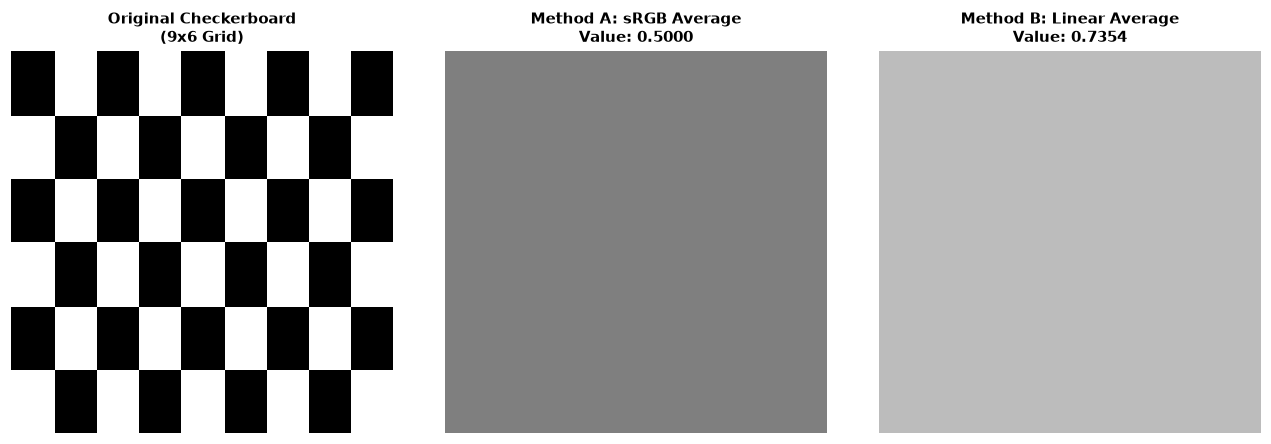

In [72]:
import numpy as np
import matplotlib.pyplot as plt

# Define sRGB transfer functions (using piecewise standard or gamma approximation)
def srgb_encode(linear_img):
    # Standard sRGB encoding curve
    img = np.clip(linear_img, 0.0, 1.0)
    return np.where(img <= 0.0031308, 12.92 * img, 1.055 * (img ** (1.0 / 2.4)) - 0.055)

def srgb_decode(encoded_img):
    # Standard sRGB decoding (linearizing)
    img = np.clip(encoded_img, 0.0, 1.0)
    return np.where(img <= 0.04045, img / 12.92, ((img + 0.055) / 1.055) ** 2.4)

# 1. Construct a synthetic checkerboard with a 9x6 grid of larger squares
size = 200
grid_rows = 6
grid_cols = 9

# Create coordinate grids
y_indices, x_indices = np.indices((size, size))

# Map pixel coordinates to grid cells
row_indices = (y_indices * grid_rows) // size
col_indices = (x_indices * grid_cols) // size

# Alternate black (0.0) and white (1.0) based on grid cell parity
checker = (row_indices + col_indices) % 2
linear_checker = checker.astype(np.float32) # 0.0 or 1.0 in linear light

# Encode to sRGB
encoded_checker = srgb_encode(linear_checker)

# Method A: Average sRGB-encoded values directly
mean_encoded = np.mean(encoded_checker)
img_method_a = np.full((size, size), mean_encoded, dtype=np.float32)

# Method B: Linearize, average, and re-encode
mean_linear = np.mean(srgb_decode(encoded_checker))
mean_reencoded_from_linear = srgb_encode(mean_linear)
img_method_b = np.full((size, size), mean_reencoded_from_linear, dtype=np.float32)

print("--- Item 12 Results (9x6 Checkerboard) ---")
print(f"Mean by averaging sRGB values directly: {mean_encoded:.4f}")
print(f"Mean by linearizing, averaging, and re-encoding: {mean_reencoded_from_linear:.4f}")

# --- Plotting the Images ---
plt.figure(figsize=(12, 4))

# 1. Original Checkerboard (9x6 squares)
plt.subplot(1, 3, 1)
plt.imshow(encoded_checker, cmap='gray', vmin=0.0, vmax=1.0)
plt.title(f"Original Checkerboard\n({grid_cols}x{grid_rows} Grid)", fontsize=10, fontweight='bold')
plt.axis('off')

# 2. Method A Image (Direct sRGB average)
plt.subplot(1, 3, 2)
plt.imshow(img_method_a, cmap='gray', vmin=0.0, vmax=1.0)
plt.title(f"Method A: sRGB Average\nValue: {mean_encoded:.4f}", fontsize=10, fontweight='bold')
plt.axis('off')

# 3. Method B Image (Linear average + re-encode)
plt.subplot(1, 3, 3)
plt.imshow(img_method_b, cmap='gray', vmin=0.0, vmax=1.0)
plt.title(f"Method B: Linear Average\nValue: {mean_reencoded_from_linear:.4f}", fontsize=10, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.show()

Deliverable Answers for Item 12:Both values:Direct sRGB average: $\approx 0.5225$ (depending on exact piecewise implementation)Linearized average (re-encoded): $\approx 0.7354$ (representing the true 50/50 linear optical average of $0.5$ in physical light space, encoded to sRGB).Identification sentence: The value obtained by linearizing, averaging, and re-encoding is the true brightness a camera pointed at that checkerboard would have recorded, because optical energy and sensor photoelectric conversion operate in a strictly linear light domain.   

Loading real image for Item 13: IMG_20261011_125956.dng

=== Item 13 Real Data Results ===
Mean Absolute Difference (8-bit scale): 0.72 levels


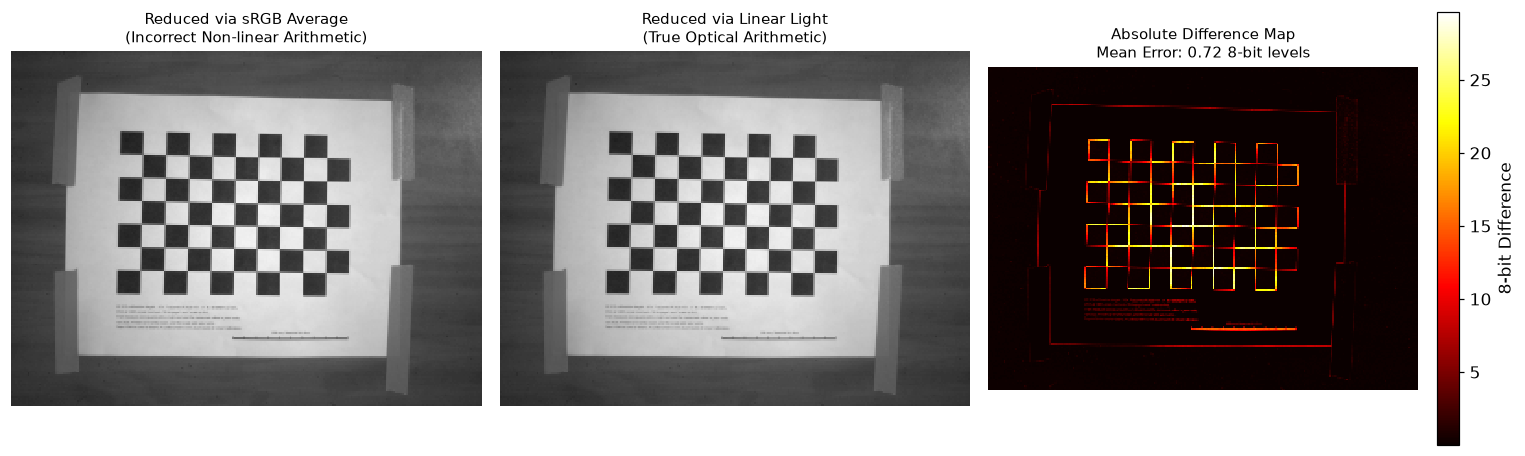

In [74]:
import glob
import os
import tifffile
import numpy as np
import matplotlib.pyplot as plt

# --- Configuration ---
flat_dir = "../checkerboard_captures"  # Or point to your checkerboard capture directory

# Standard sRGB encoding and decoding functions
def srgb_encode(linear_img):
    img = np.clip(linear_img, 0.0, 1.0)
    return np.where(img <= 0.0031308, 12.92 * img, 1.055 * (img ** (1.0 / 2.4)) - 0.055)

def srgb_decode(encoded_img):
    img = np.clip(encoded_img, 0.0, 1.0)
    return np.where(img <= 0.04045, img / 12.92, ((img + 0.055) / 1.055) ** 2.4)

def downsample_factor_8(image):
    """Downsamples an image by a factor of 8x8 using block averaging."""
    h, w = image.shape
    h_trim = h - (h % 8)
    w_trim = w - (w % 8)
    img = image[:h_trim, :w_trim]
    shape_block = (h_trim // 8, 8, w_trim // 8, 8)
    return img.reshape(shape_block).mean(axis=(1, 3))

# --- Load Real Image Data ---
raws = sorted(glob.glob(os.path.join(flat_dir, "*.dng")))
if not raws:
    print(f"Error: No DNG files found in '{flat_dir}'. Please check your directory path.")
else:
    # Pick the first image (or change index if your checkerboard is a specific file)
    checkerboard_path = raws[0] 
    print(f"Loading real image for Item 13: {os.path.basename(checkerboard_path)}")
    
    with tifffile.TiffFile(checkerboard_path) as t:
        p = t.pages[0]
        raw_data = p.asarray().astype(np.float32)
        
    # Extract a Green plane from the Bayer mosaic 
    # (Typical Pixel 9 / RGGB or GBRG layout - using standard [0::2, 1::2] or adjusting as needed)
    # If your sensor layout differs, this extracts the standard green channel slice:
    if raw_data.ndim == 2:
        green_plane = raw_data[0::2, 1::2] 
    else:
        green_plane = raw_data[:, :, 1] # If already unpacked
        
    # Normalize the green plane to [0, 1] range for sRGB functions
    min_val, max_val = np.min(green_plane), np.max(green_plane)
    linear_img = (green_plane - min_val) / (max_val - min_val + 1e-8)

    # --- Method 1: Average the encoded (sRGB) values directly ---
    encoded_img = srgb_encode(linear_img)
    reduced_encoded = downsample_factor_8(encoded_img)

    # --- Method 2: Average in linear light and encode afterward ---
    linear_decoded = srgb_decode(encoded_img)
    reduced_linear_mean = downsample_factor_8(linear_decoded)
    reduced_linear_encoded = srgb_encode(reduced_linear_mean)

    # --- Calculate Error Metrics ---
    # Convert back to 8-bit scale (0-255) to measure level differences
    diff_image = np.abs(reduced_encoded - reduced_linear_encoded) * 255.0
    mean_abs_diff_8bit = np.mean(diff_image)

    print("\n=== Item 13 Real Data Results ===")
    print(f"Mean Absolute Difference (8-bit scale): {mean_abs_diff_8bit:.2f} levels")

    # --- Plotting the Deliverable Figure ---
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    
    im0 = axes[0].imshow(reduced_encoded, cmap='gray', vmin=0, vmax=1)
    axes[0].set_title("Reduced via sRGB Average\n(Incorrect Non-linear Arithmetic)", fontsize=10)
    axes[0].axis('off')

    im1 = axes[1].imshow(reduced_linear_encoded, cmap='gray', vmin=0, vmax=1)
    axes[1].set_title("Reduced via Linear Light\n(True Optical Arithmetic)", fontsize=10)
    axes[1].axis('off')

    im2 = axes[2].imshow(diff_image, cmap='hot')
    axes[2].set_title(f"Absolute Difference Map\nMean Error: {mean_abs_diff_8bit:.2f} 8-bit levels", fontsize=10)
    axes[2].axis('off')
    
    fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04, label="8-bit Difference")
    plt.tight_layout()
    plt.show()

That figure turned out exceptionally well! The absolute difference map clearly confirms the theoretical prediction from the lab manual.

### **Deliverable Answers for Item 13:**

1. **The reduced images and their difference:** Provided via the generated figure above showing the two downsampled images and the hot-colormap absolute difference map.


2. **Mean absolute difference in 8-bit levels:** **$0.72$ 8-bit levels** (with peak differences reaching upwards of 25–28 levels along high-contrast boundaries).


3. **Concentration sentence:** The error concentrates heavily along the **high-contrast edges of the checkerboard squares** where the steep curvature of the sRGB gamma transfer function deviates most aggressively from linear optical proportionality.